# GEOG 3155 6155 Lab 06

# Introduction

In previous labs, we've explore supervised machine learning, where we have a *target*: a variable (`y`) that we want to predict as a function of a set of features (`X`). In this lab, we'll explore unsupervised learning, where there is no distinct target. These methods are generally used to explore complex data by reducing it in some way; either by reducing the number of variables or dimensions, or by grouping observations into clusters. Here, we'll look at three clustering methods:

-   $k$-means clustering
-   Hierarchical clustering
-   Self-organizing maps

The data we will use is from the [Gap Minder project](https://www.gapminder.org). While you can download the individual variables from the web site, we will use a preprocessed set of the data covering the period 1801-2018, in the file *gapminder_1800_2018.csv*. Download this to your `datafiles` folder and make a new folder for today's class called `lab06`. You will also need the shapefile of country borders: `ne_50m_admin_0_countries.shp` (you should have this from a previous lab).

## Objectives

- Set up data to run different unsupervised classification methods
- Understand and work with the output
- Use self-organizing maps with geographical data


# Lab set up

Standard clustering methods are available through **scikit-learn**, and we'll use those here for the first part of the lab. There are a number of packages for self-organizing maps in Python (e.g. **sompy**, **susi**). For this lab, we'll use **minisom**, a fairly minimalist implmentation. If you are using these methods in practice, it would be worth exploring other options. We'll also need the **country_converter** package to help with labeling the data, so use `conda` or `pip` to install both of these before proceeding. 

Let's begin by importing the packages we'll need for the lab:

In [1]:
import pandas as pd
import numpy as np
import sklearn
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="white")
sns.set(style="whitegrid", color_codes=True)
## Set random seed for reproducibility
np.random.seed(1234)

### Data processing

The data we will use is from the [Gap Minder project][gapID]. While you can download the individual variables from the web site, we will use a preprocessed set of the data covering the period 1801-2018, in the file *gapminder_1800_2018.csv*. 

In [2]:
gap_df = pd.read_csv("./datafiles/gapminder_1800_2018.csv")
gap_df.shape

(58695, 8)

In [3]:
gap_df.head()

,country,year,child_mortality,fertility,per_cap_co2,income,life_expectancy,population
0,Afghanistan,1800,469.0,7.0,NaN,603.0,28.2,3280000
1,Afghanistan,1801,469.0,7.0,NaN,603.0,28.2,3280000
2,Afghanistan,1802,469.0,7.0,NaN,603.0,28.2,3280000
3,Afghanistan,1803,469.0,7.0,NaN,603.0,28.2,3280000
4,Afghanistan,1804,469.0,7.0,NaN,603.0,28.2,3280000


We can now make some plots to look at the data. First, histograms of the six features that we are going to use (child mortality, fertility, per capita CO2 emissions, GDP per capita, life expectancy and population size):

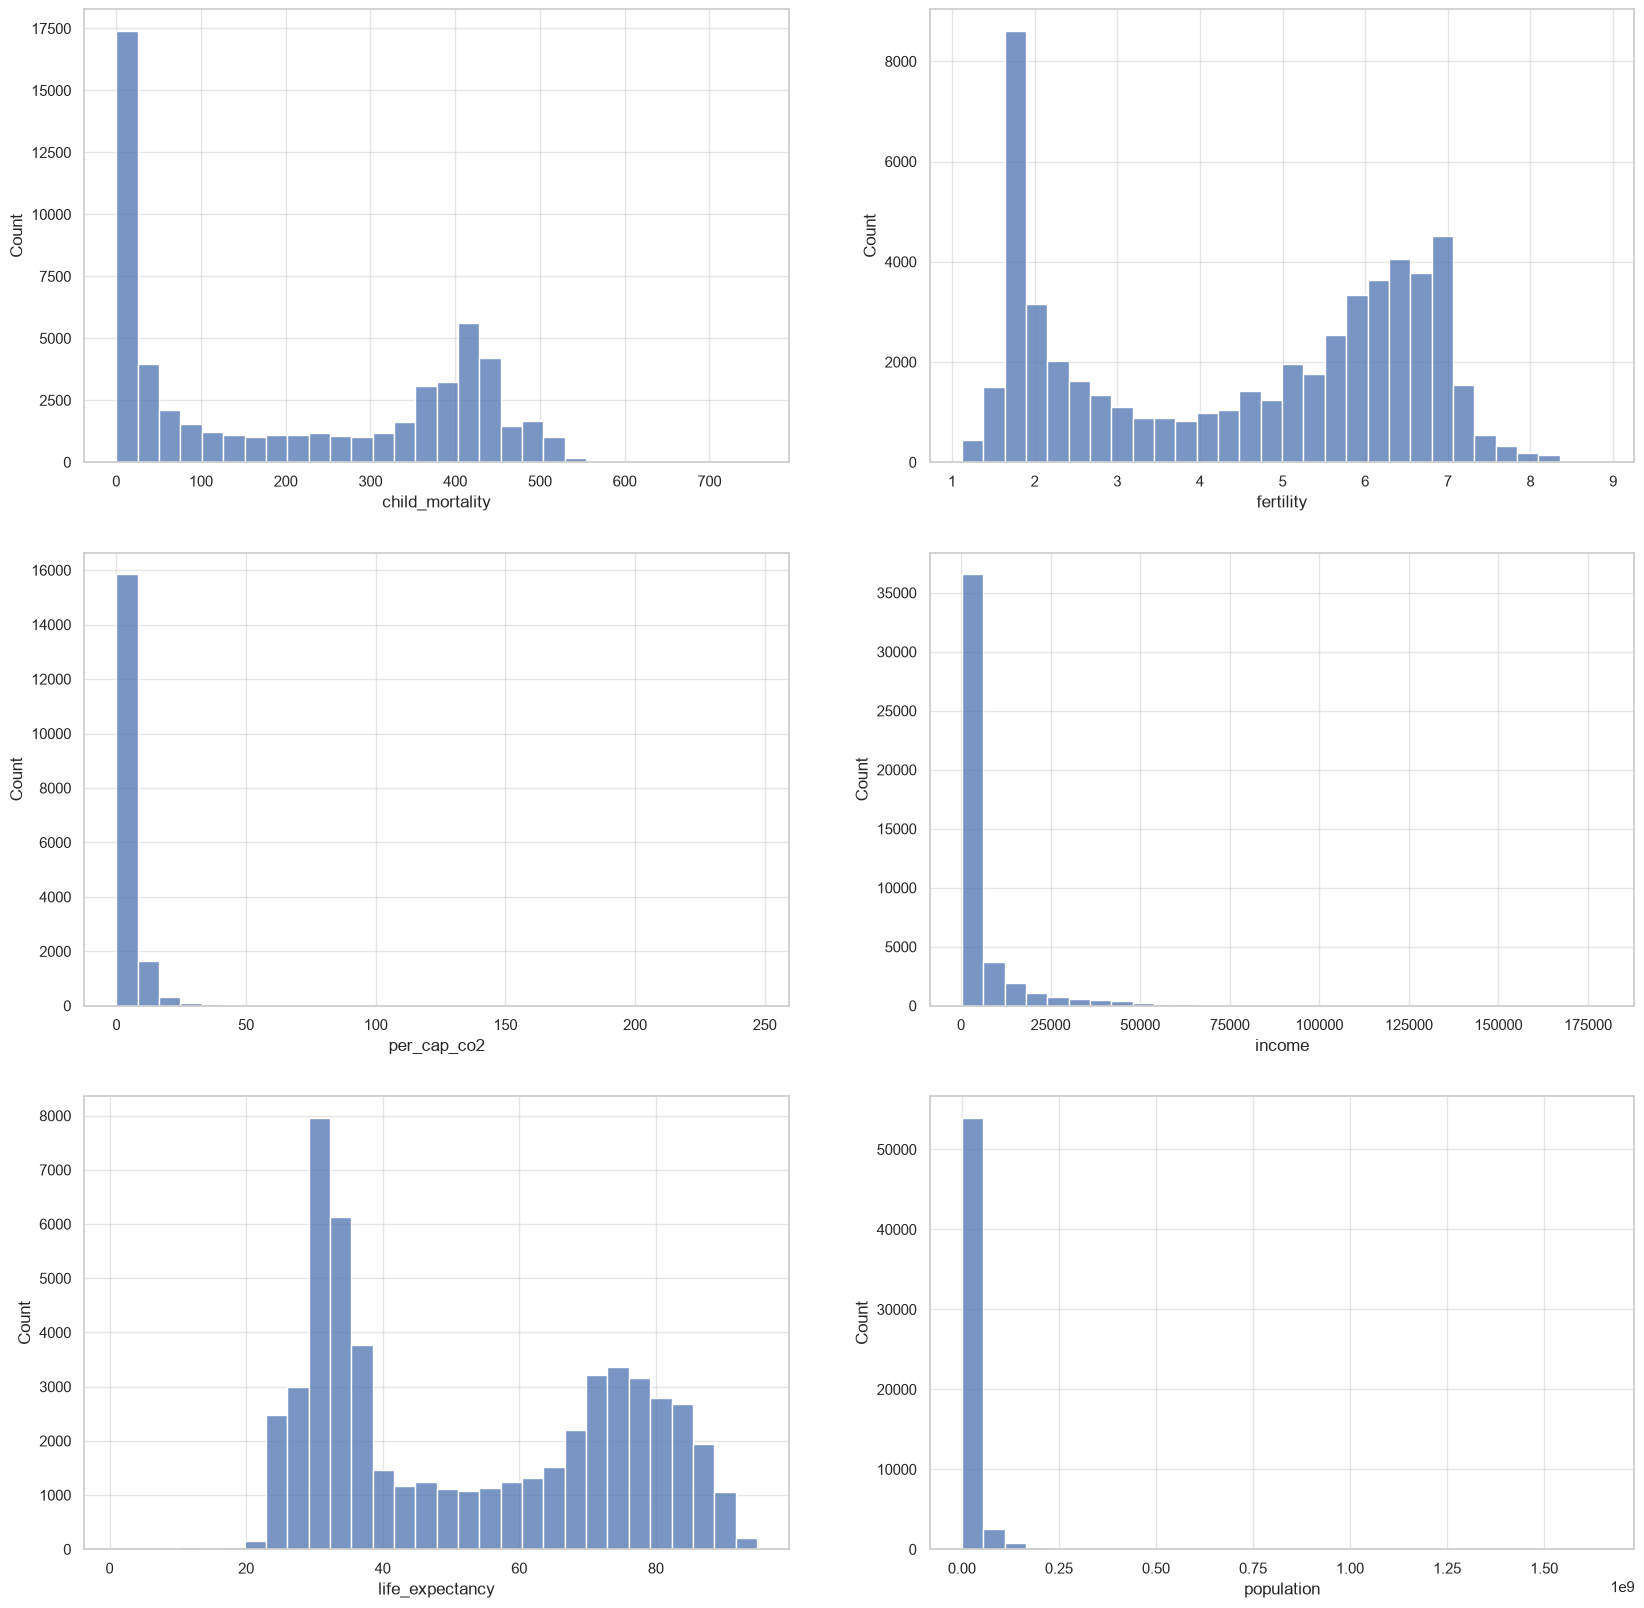

In [4]:
fig = plt.figure(figsize=(20,20))

fig.add_subplot(321)
sns.histplot(data=gap_df, x="child_mortality", bins=30)

fig.add_subplot(322)
sns.histplot(data=gap_df, x="fertility", bins=30)

fig.add_subplot(323)
sns.histplot(data=gap_df, x="per_cap_co2", bins=30)

fig.add_subplot(324)
sns.histplot(data=gap_df, x="income", bins=30)

fig.add_subplot(325)
sns.histplot(data=gap_df, x="life_expectancy", bins=30)

fig.add_subplot(326)
sns.histplot(data=gap_df, x="population", bins=30)

plt.show()

The histograms clearly show skew in most of the variables, and we will need to transform the data before analyzing it. We'll do this in two steps. First, we'll remove rows with missing observations (we could potentially impute these, but that is a little more difficult for time series data). We also remove any row where the per capita CO2 emissions are zero, partly because this would cause problems when log-transforming and partly because this is clearly not true. 

In [5]:
gap_df = gap_df.dropna()

gap_df_scale = gap_df[gap_df["per_cap_co2"] > 0].copy()

gap_df.shape

(17737, 8)

Next, we'll log transform all variables to remove the skew, then transform each variable to a $z$-scores by subtracting the mean and dividing by the standard deviation. To simplify things, we can do all of this in a loop by first defining the names of the columns that we want to transform. 

In [6]:
cols = ["child_mortality", "fertility", "per_cap_co2", 
        "income", "life_expectancy", "population"]

for col in cols:
    gap_df_scale[col] = np.log(gap_df_scale[col])
    gap_df_scale[col] = (gap_df_scale[col] - gap_df_scale[col].mean())/gap_df_scale[col].std()

Check the values you got (the means should be close to zero and the std. deviation close to 1):

In [7]:
gap_df_scale.describe()

,year,child_mortality,fertility,per_cap_co2,income,life_expectancy,population
count,17676.000000,1.767600e+04,1.767600e+04,1.767600e+04,1.767600e+04,1.767600e+04,1.767600e+04
mean,1958.988572,5.651862e-16,3.215853e-17,1.768719e-17,-9.358132e-16,1.816957e-16,9.872669e-16
std,45.969689,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
min,1800.000000,-3.081631e+00,-2.539307e+00,-4.556951e+00,-2.347217e+00,-8.299730e+00,-3.016228e+00
25%,1935.000000,-7.273651e-01,-8.185993e-01,-6.579271e-01,-7.369487e-01,-6.842808e-01,-5.381645e-01
50%,1970.000000,2.277006e-01,2.839114e-01,1.109823e-01,-1.193879e-01,2.542653e-01,2.198329e-02
75%,1994.000000,8.551855e-01,8.647610e-01,7.982361e-01,6.857548e-01,8.360962e-01,6.364680e-01
max,2018.000000,1.552980e+00,1.577167e+00,2.741626e+00,3.250036e+00,1.459600e+00,3.113488e+00


The very last thing we'll do is to extract a single year of data for the first part of the lab (just 2018), and convert it to a NumPy array:

In [8]:
gap_df_scale2 = gap_df_scale[gap_df_scale.year == 2018]

X = gap_df_scale2[cols].values

## $k$-means clustering

We'll next use these data with the $k$-means cluster algorithm. Scikit-learn has several clustering algorithms in the `cluster` submodule, and the one we need is `KMeans()`. 

In [9]:
from sklearn.cluster import KMeans

We now initialize this with the following parameters: a random initialization of the cluster centroids, 6 clusters. We'll get the algorithm to run 10 times to try and avoid sub-optimal cluster solutions. (Note that the default initialization in `KMeans` is through  $k$-means++, which generally better starting solutions, and you should probably use that with your own data):

In [10]:
kmeans = KMeans(init="random", n_clusters=6, n_init=10, random_state=42)

We can now use the `fit()` function to run the algorithm and find the clusters.

In [11]:
kmeans.fit(X)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",6
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'random'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](6, 6)","[[-0.66,

Once run, the object it creates has several useful attributes. We can see how many iterations it took before convergence:

In [12]:
kmeans.n_iter_

8

And we can see the cluster assignments for each country in `labels_`:

In [13]:
labels = kmeans.labels_
print(labels)

[4 5 3 4 5 1 5 1 2 3 5 2 3 5 2 2 5 4 5 3 2 5 1 5 2 4 4 3 4 1 5 4 4 1 1 3 0
 4 4 2 4 2 3 2 2 2 0 3 3 3 3 0 4 2 0 4 5 2 1 0 4 5 1 4 2 5 3 4 4 5 4 3 2 2
 3 3 1 3 2 2 1 5 1 3 1 4 0 2 3 3 2 2 0 4 2 2 2 4 4 1 5 4 5 4 5 1 0 5 5 5 3
 4 3 0 3 2 2 3 4 4 3 5 2 2 3 0 5 4 3 3 3 1 2 2 1 1 4 0 0 1 4 2 5 4 2 2 2 0
 4 3 1 4 1 3 5 5 4 5 2 2 3 4 4 1 0 4 0 5 3 1 3 4 3 2 1 1 2 3 0 3 3 4 4 4]


And we can use this to see the size of each cluster (the number of observations assigned to each cluster)

In [14]:
counts = np.bincount(labels)
pd.DataFrame({"cluster": np.arange(0,6), "counts": counts})

,cluster,counts
0,0,16
1,1,24
2,2,38
3,3,37
4,4,41
5,5,28


And finally the `cluster_centers_`. These are the prototypes; the average value of each variable for all the observations assigned to a given cluster (note these are the log-transformed and scaled data)

In [15]:
centers = kmeans.cluster_centers_
pd.DataFrame(centers, columns = cols)

,child_mortality,fertility,per_cap_co2,income,life_expectancy,population
0,-0.658999,-0.202518,0.043897,0.076611,0.706836,-1.187704
1,-2.068506,-1.663023,1.067624,1.645427,1.215213,1.403312
2,-2.343935,-1.702729,1.062190,1.820488,1.246769,-0.078553
3,-1.088292,-1.031533,0.402711,0.475124,0.987209,0.910225
4,-0.214312,0.265726,-0.578730,-0.692771,0.536862,0.617443
5,-1.453582,-1.456163,0.673031,1.043913,1.043382,-1.098190


Here, we can see that cluster 0, for example, has the lowest life expectancy and GDP, as well as high infant mortality and fertility rates. 

### Maps

As these are spatial data, we can now plot the distribution of the clusters. First, we'll load the world shapefile in the `ne_50m_admin_0_countries` folder (we used this in a previous lab). Load this using geopandas:

In [16]:
import geopandas as gpd
borders = gpd.read_file("./datafiles/ne_50m_admin_0_countries/ne_50m_admin_0_countries.shp")
borders.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

In [17]:
borders.columns

Index(['featurecla', 'scalerank', 'LABELRANK', 'SOVEREIGNT', 'SOV_A3',
       'ADM0_DIF', 'LEVEL', 'TYPE', 'ADMIN', 'ADM0_A3', 'GEOU_DIF', 'GEOUNIT',
       'GU_A3', 'SU_DIF', 'SUBUNIT', 'SU_A3', 'BRK_DIFF', 'NAME', 'NAME_LONG',
       'BRK_A3', 'BRK_NAME', 'BRK_GROUP', 'ABBREV', 'POSTAL', 'FORMAL_EN',
       'FORMAL_FR', 'NAME_CIAWF', 'NOTE_ADM0', 'NOTE_BRK', 'NAME_SORT',
       'NAME_ALT', 'MAPCOLOR7', 'MAPCOLOR8', 'MAPCOLOR9', 'MAPCOLOR13',
       'POP_EST', 'POP_RANK', 'GDP_MD_EST', 'POP_YEAR', 'LASTCENSUS',
       'GDP_YEAR', 'ECONOMY', 'INCOME_GRP', 'WIKIPEDIA', 'FIPS_10_', 'ISO_A2',
       'ISO_A3', 'ISO_A3_EH', 'ISO_N3', 'UN_A3', 'WB_A2', 'WB_A3', 'WOE_ID',
       'WOE_ID_EH', 'WOE_NOTE', 'ADM0_A3_IS', 'ADM0_A3_US', 'ADM0_A3_UN',
       'ADM0_A3_WB', 'CONTINENT', 'REGION_UN', 'SUBREGION', 'REGION_WB',
       'NAME_LEN', 'LONG_LEN', 'ABBREV_LEN', 'TINY', 'HOMEPART', 'MIN_ZOOM',
       'MIN_LABEL', 'MAX_LABEL', 'NE_ID', 'WIKIDATAID', 'NAME_AR', 'NAME_BN',
       'NAME_DE', 'NAME_

Next, we add the cluster assignments to the `gap_df_scale2` data frame:

In [18]:
gap_df_scale2['kmeans'] = labels

Now we need to merge the `gap_df_scale2` data frame with the world borders spatial object. To do this, we add a new column to the data frame containing the ISO3 standard country codes, using the convenient **country_converter** package (you'll need to install this). This contains several useful functions, including `convert()`, which takes a list of country names (or abbreviations) and matches them to standard names or codes.

In [20]:
import country_converter as coco
gap_iso3 = coco.convert(names=gap_df_scale2.country, to='ISO3', not_found=None)
gap_df_scale2 = gap_df_scale2.assign(ISO_A3 = gap_iso3)

Finally, we use these ISO codes to merge the two datasets. We need to specify the column name for each dataset that contains the label to be used in merging, which we do with `on`. 

In [21]:
borders2 = borders.merge(gap_df_scale2, on='ISO_A3')

Finally, we can plot out the clusters, which highlights the position of this poorer cluster 0 in Saharan and sub-Saharan Africa:

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

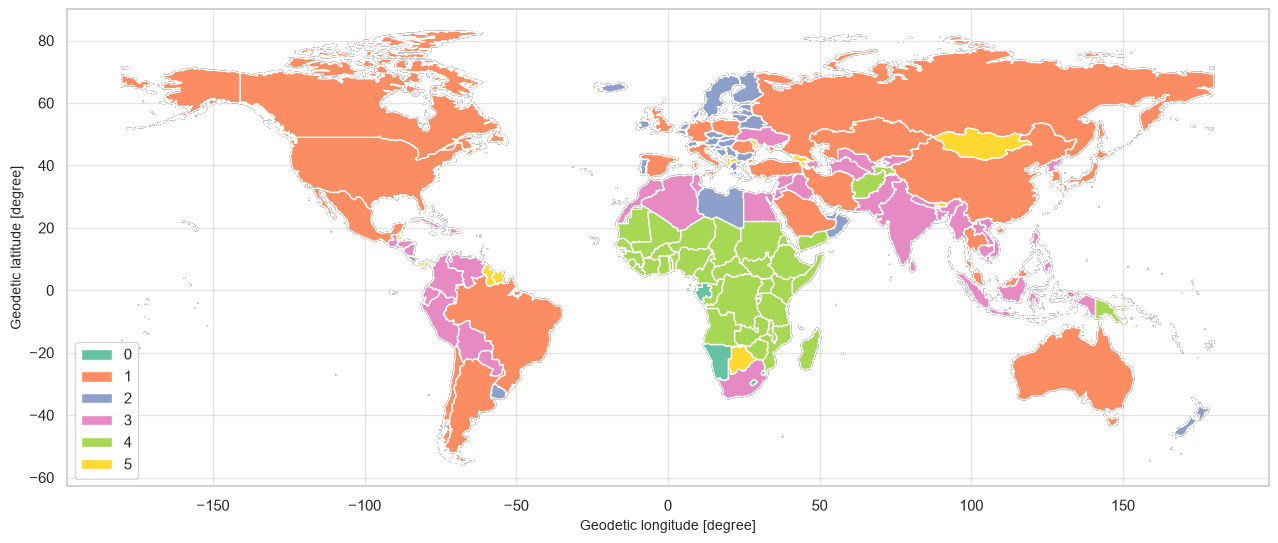

In [22]:
base = borders2.plot(figsize = (15.5, 9.5), edgecolor="black", facecolor="None")
borders2.plot(ax = base, column = 'kmeans', categorical=True, 
             cmap = 'Set2', legend = True, legend_kwds={'loc': 'lower left'})

## Hierarchical cluster analysis

We'll briefly demonstrate the use of hierarchical clustering here, using the `AgglomerativeClustering` function from scikit-learn's clustering module. 

In [23]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram

This works in the same way as other scikit-learn algorithms. We first initialize the method. The two parameters we set here calculates the full hierarchy, as we do not specify a cluster number. We then use the `fit()` method with our training data `X`. 

In [24]:
hclust = AgglomerativeClustering(distance_threshold=0, n_clusters=None)
hclust = hclust.fit(X)

Scikit-learn does not have a built in function to plot the dendrogram, but we can use the following code provided on their website to create a function to do so. 

In [25]:
def plot_dendrogram(model, **kwargs):
    # Create linkage matrix and then plot the dendrogram

    # create the counts of samples under each node
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # leaf node
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack([model.children_, model.distances_,
                                      counts]).astype(float)

    # Plot the corresponding dendrogram
    dendrogram(linkage_matrix, **kwargs)

And now use this to plot the results:

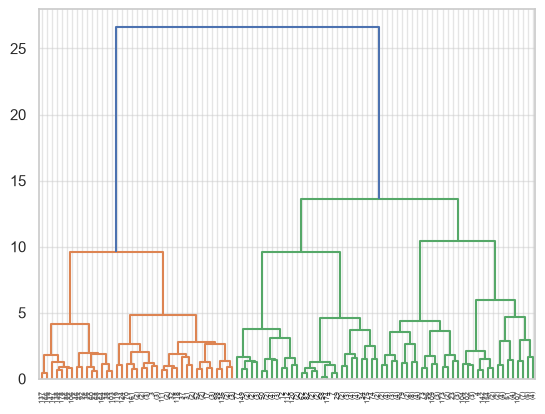

In [26]:
plot_dendrogram(hclust, truncate_mode='level', p=6)

While this gives us the full hierarchy, we don't have the cluster assignments for each country. To get clusters labels for a given number of groups, re-run the `AgglomerativeClustering` with `n_clusters` set to the number required. We then can use the `fit_predict()` method to get a vector of cluster assignments.

In [27]:
hclust = AgglomerativeClustering(n_clusters = 6)
hclust.fit_predict(X)

array([2, 0, 4, 2, 0, 1, 0, 1, 3, 0, 0, 3, 4, 0, 3, 3, 0, 2, 0, 4, 3, 0,
       1, 3, 3, 2, 2, 4, 2, 1, 0, 2, 2, 1, 1, 1, 5, 2, 5, 0, 2, 3, 3, 3,
       3, 3, 5, 0, 0, 4, 4, 0, 2, 3, 0, 2, 0, 3, 1, 0, 5, 0, 1, 2, 3, 0,
       4, 2, 5, 0, 2, 4, 3, 3, 1, 1, 1, 4, 3, 3, 1, 0, 1, 4, 3, 2, 5, 3,
       4, 4, 3, 3, 5, 2, 0, 3, 3, 2, 2, 1, 0, 2, 0, 5, 0, 1, 5, 0, 0, 3,
       4, 2, 4, 0, 4, 3, 3, 4, 2, 2, 4, 0, 3, 3, 2, 4, 0, 2, 0, 1, 4, 1,
       3, 3, 1, 1, 2, 5, 5, 3, 2, 3, 0, 2, 3, 3, 3, 5, 2, 4, 1, 2, 1, 1,
       0, 0, 2, 0, 3, 3, 4, 2, 2, 1, 5, 2, 5, 3, 0, 1, 0, 2, 1, 3, 1, 1,
       0, 4, 5, 4, 4, 2, 2, 2])

The clusters that you obtain can be used in the same way that we used the $k$-means clusters. Here, we'll append them to the country borders and map them out:

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

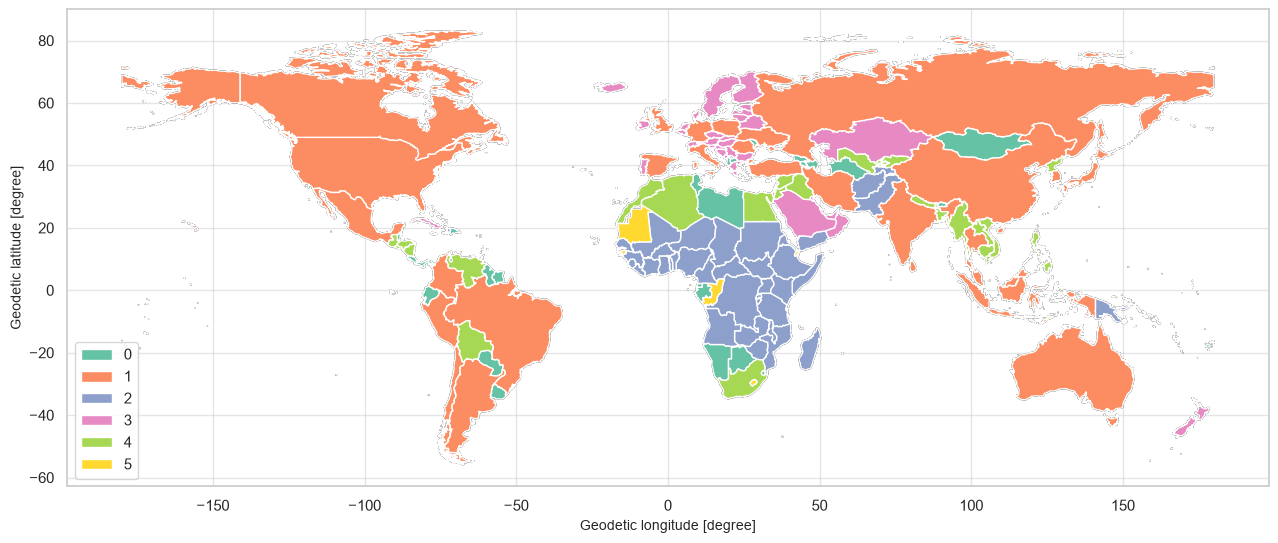

In [28]:
gap_df_scale2 = gap_df_scale2.assign(hclust = hclust.fit_predict(X))

borders2 = borders.merge(gap_df_scale2, on='ISO_A3')
base = borders2.plot(figsize = (15.5, 9.5), edgecolor="black", facecolor="None")
borders2.plot(ax = base, column = 'hclust', categorical=True, 
             cmap = 'Set2', legend = True, legend_kwds={'loc': 'lower left'})

## Self-organizing maps

We'll now repeat this analysis with a self-organizing map (SOM), but using the full dataset. Unfortunately, there is no existing method for this in scikit-learn, so we'll use the **MiniSom** package:

In [30]:
from minisom import MiniSom

We next need to create our training data by selecting the set of columns we want to use (`cols`) and converting the results into a NumPy array:

In [31]:
X = gap_df_scale[cols].values
X.shape

(17676, 6)

Now we can set up the self-organizing map. This follows a very similar process to scikit-learn. First, we initialize the grid and various parameters that control the learning:

- The first two values define the horizontal and vertical size of the SOM grid
- The next value defines the number of input features
- `sigma` specifies the size the neighborhood radius. This has been set to quite a high value here to force a relatively smooth organization
- `learning_rate` controls the rate of update to each nodes weights. Both this and `sigma` are reduced over the training period to focus on finer scale patterns in the data
- `neighborhood_function` defines the shape of spatial decay in the neighborhood updates
- `topology` is either rectangular or hexagonal. Note the any visualization of the hexagonal topology will appear rectangular due to limits in the package

In [32]:
som = MiniSom(30, 20, X.shape[1], sigma=10., learning_rate=.75, 
              neighborhood_function='gaussian', topology = 'hexagonal',
              random_seed=0)

Once the SOM is set up, we initialize the weights of each node randomly, then train it with the training data for 10000 iterations. 

In [33]:
som.random_weights_init(X)
som.train(X, 10000, verbose=True)  # random training

 [ 10000 / 10000 ] 100% - 0:00:00 left 
 quantization error: 1.0770046317597044


This function does not provide a way to visualize the changes fit of the SOM to the data over the set of iterations. The appendix contains code that will allow you to track and plot this, but it is fairly time consuming so we'll skip it here. 

Instead, we can start to plot some of the outputs. First, we'll plot the U-matrix, a representation of the dissimilarity between each node and it's immediate neighbors. This shows the non-linearity of the new representation of the data, with some regions of quite high values (high dissimilarity) dividing up the map.

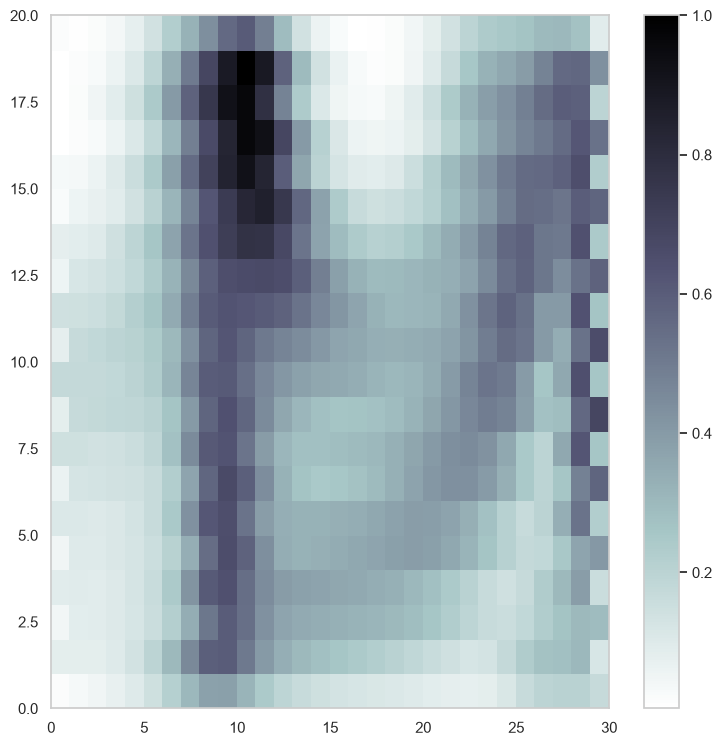

In [34]:
plt.figure(figsize=(9, 9))
plt.pcolor(som.distance_map().T, cmap='bone_r')
plt.colorbar()

Next, we'll plot the codebook vectors. These are the weights associated with each feature, and can be used to interpret the organization of the SOM. First, we need to extract these from the trained SOM using `get_weights()`:

In [35]:
som_weights = som.get_weights()

som_weights.shape

(30, 20, 6)

We can plot out the weights for individual feature weights as a heatmap to illustrate the gradients in the map, and to help in interpreting the results. Here we plot all six together:

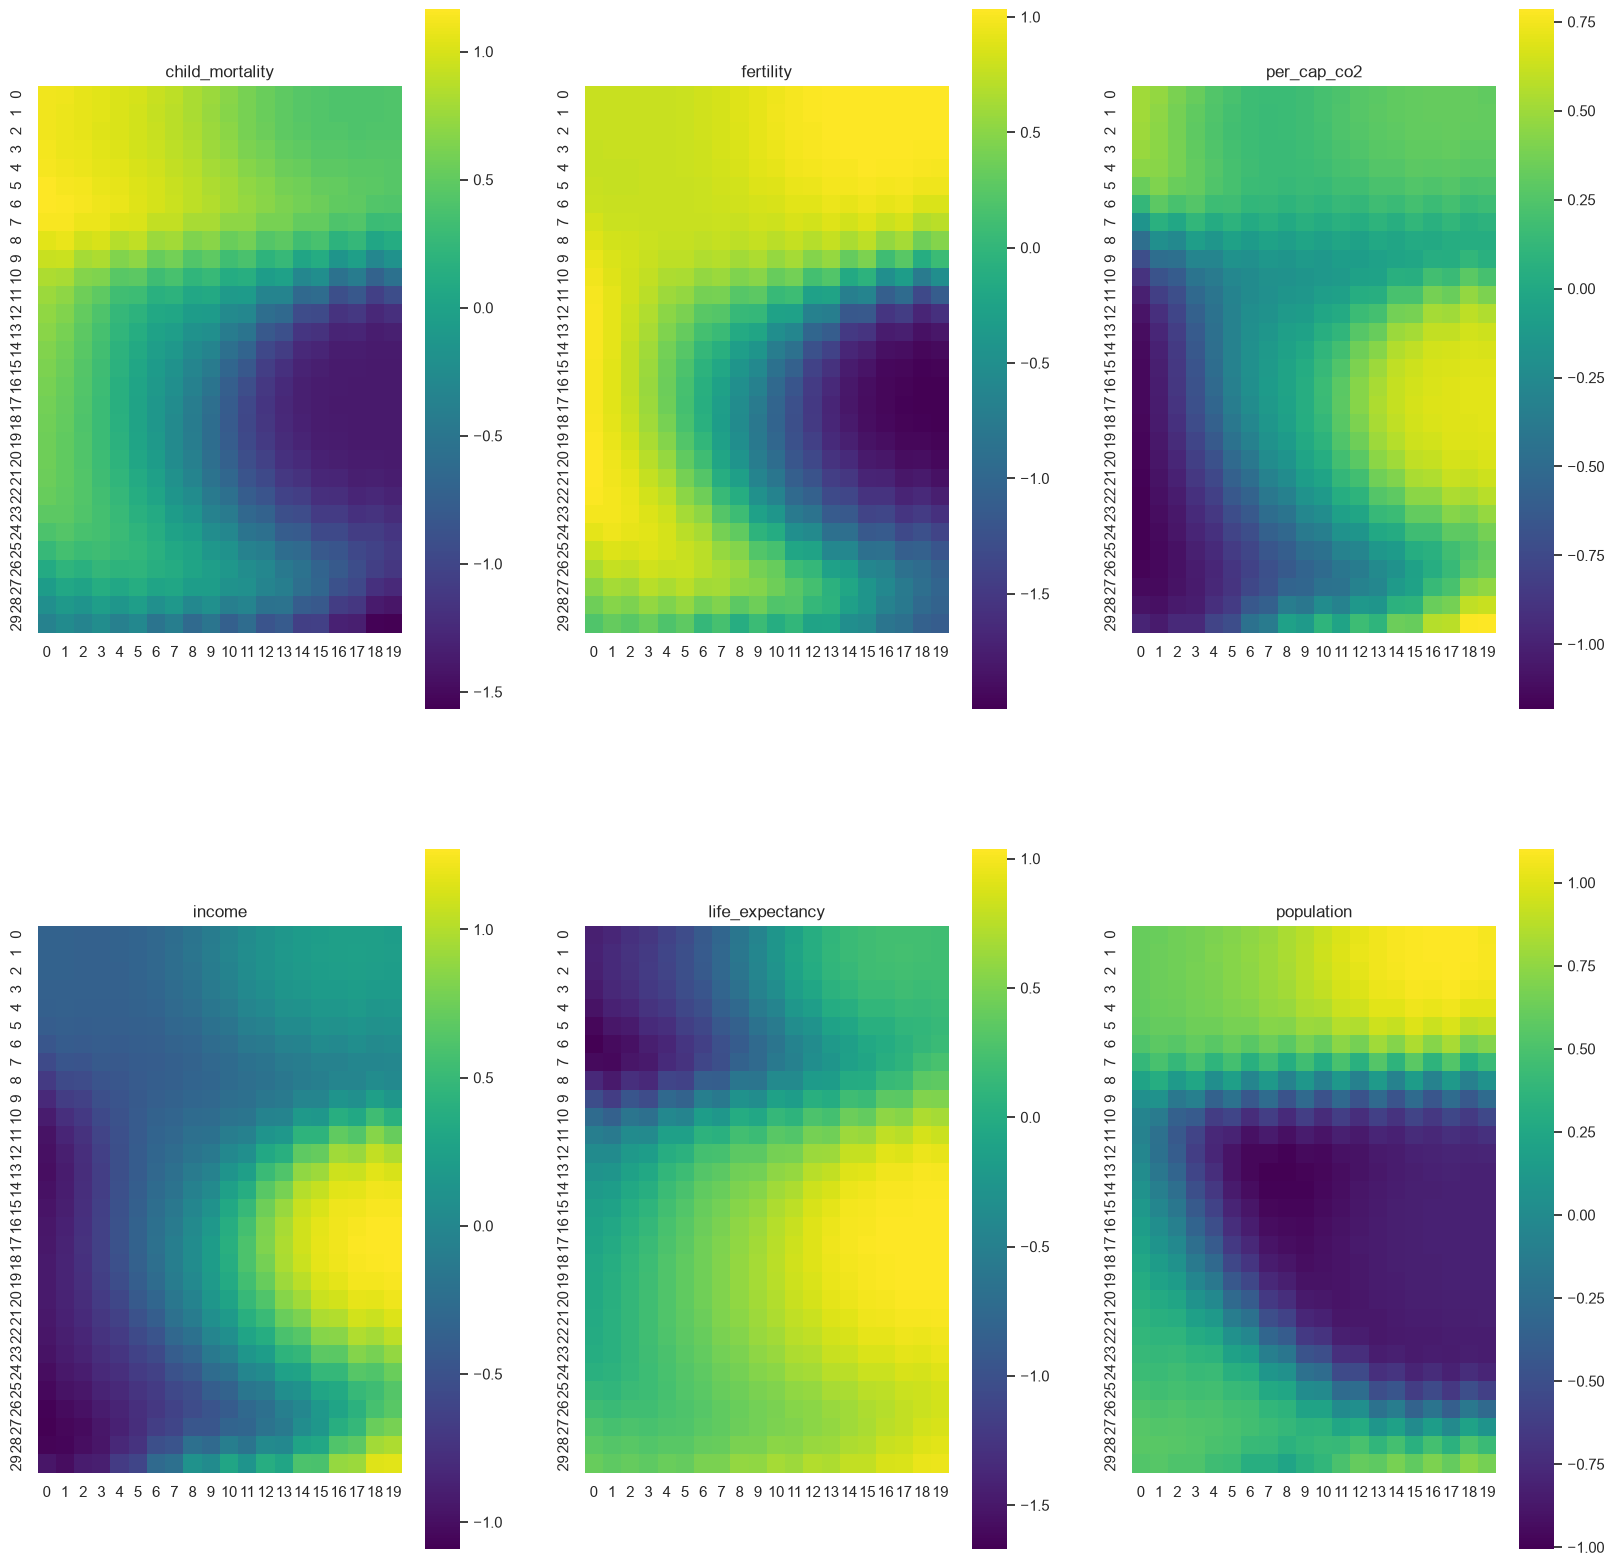

In [36]:
fig = plt.figure(figsize=(20,20))

ax1 = fig.add_subplot(231, aspect='equal')
plot_var = 0
sns.heatmap(som_weights[:,:,plot_var], cmap="viridis")
ax1.set_title(cols[plot_var])

ax2 = fig.add_subplot(232, aspect='equal')
plot_var = 1
sns.heatmap(som_weights[:,:,plot_var], cmap="viridis")
ax2.set_title(cols[plot_var])

ax3 = fig.add_subplot(233, aspect='equal')
plot_var = 2
sns.heatmap(som_weights[:,:,plot_var], cmap="viridis")
ax3.set_title(cols[plot_var])

ax4 = fig.add_subplot(234, aspect='equal')
plot_var = 3
sns.heatmap(som_weights[:,:,plot_var], cmap="viridis")
ax4.set_title(cols[plot_var])

ax5 = fig.add_subplot(235, aspect='equal')
plot_var = 4
sns.heatmap(som_weights[:,:,plot_var], cmap="viridis")
ax5.set_title(cols[plot_var])

ax6 = fig.add_subplot(236, aspect='equal')
plot_var = 5
sns.heatmap(som_weights[:,:,plot_var], cmap="viridis")
ax6.set_title(cols[plot_var])

plt.show()

The main gradient is between the left of the map, with low life expectancy, high child mortality and low per capita income and CO2 emissions. The right hand side of the map shows values that are largely the opposite of this. There are two clear areas of high income and life expectancy on the right; if you look at the population map, you should see that these correspond to rich countries with high and low population sizes. 

We can now run a cluster analysis on these results to simplify the map. The SOM weights are held in a 3D array (the third dimension corresponds to the features). If this is reshaped into a 2D array, with each row corresponding to a SOM node, and each column to a feature, we can then use this to train a cluster method (we'll use hierarchical clustering here):

In [37]:
X_som = som_weights.reshape(600,6)

hclust = AgglomerativeClustering(n_clusters = 6)
som_clust = hclust.fit_predict(X_som)

We can now plot out these clusters. Note that as we have clustered the SOM nodes (not the original observations), we can't yet visualize these on a map, but we can replot the SOM grid and shade each node by it's cluster membership:

<Axes: >

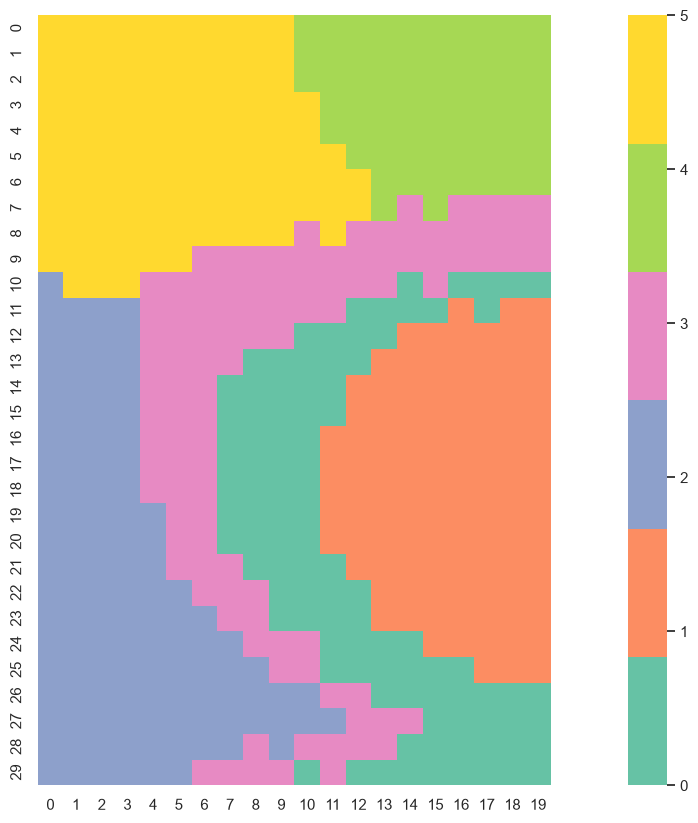

In [38]:
clus_cmap = sns.color_palette("Set2", 6)

fig = plt.figure(figsize=(20,10))
ax = fig.add_subplot(111, aspect='equal')
sns.heatmap(som_clust.reshape(30,20), cmap=clus_cmap)

As we have data over multiple years, we can also use the results of the SOM analysis to track the change made by an individual country over time. To do this, we need to know which node a country was assigned to for each of it's time steps. For this, we can take advantage of the `winner()` method. This returns the grid coordinates for the best matching unit for any observation. For example, to find the BMU for the first value in X:

In [39]:
som.winner(X[0,:])

(np.int64(10), np.int64(0))

To do this for all observations for a country, we first make a new dataset corresponding to that country (e.g. here for the United States)

In [40]:
X_country = X[gap_df_scale['country'] == "United States", :]
X_country.shape

(219, 6)

Next, we need to find the node assigned to each of those observations using the `winner()` method. As this only works for a single observation, we create a simple method that we can then use with NumPy's `apply_along_axis()` function. 

In [41]:
def get_node_crds( x ):
    return som.winner(x)
country_crds = np.apply_along_axis( get_node_crds, axis=1, arr=X_country )
country_crds

array([[10,  0],
       [10,  0],
       [10,  0],
       [10,  0],
       [10,  0],
       [10,  0],
       [10,  0],
       [10,  0],
       [10,  0],
       [ 9,  0],
       [ 9,  0],
       [ 9,  0],
       [ 9,  0],
       [ 9,  0],
       [ 9,  0],
       [ 9,  0],
       [ 9,  0],
       [ 9,  0],
       [ 9,  0],
       [ 9,  0],
       [ 9,  0],
       [ 9,  0],
       [ 9,  0],
       [ 9,  0],
       [ 9,  0],
       [ 9,  0],
       [ 9,  0],
       [ 9,  0],
       [ 9,  0],
       [ 9,  0],
       [ 9,  0],
       [ 8,  0],
       [ 8,  0],
       [ 8,  0],
       [ 8,  0],
       [ 8,  0],
       [ 8,  0],
       [ 7,  7],
       [ 8,  0],
       [ 7,  7],
       [ 7,  7],
       [ 7,  7],
       [ 7,  7],
       [ 6,  7],
       [ 6,  7],
       [ 6,  7],
       [ 6,  7],
       [ 6,  7],
       [ 4,  6],
       [ 4,  6],
       [ 4,  6],
       [ 4,  6],
       [ 2,  5],
       [ 2,  5],
       [ 2,  5],
       [ 1,  5],
       [ 1,  5],
       [ 1,  5],
       [ 1,  5

Now we plot out the grid again, shaded with the cluster assignments. Then we use matplotlib's `plot()` function to overlay the country's trajectory. We also add a text label for the first and last observation to illustrate the start and end.

Text(18, 29, '2018')

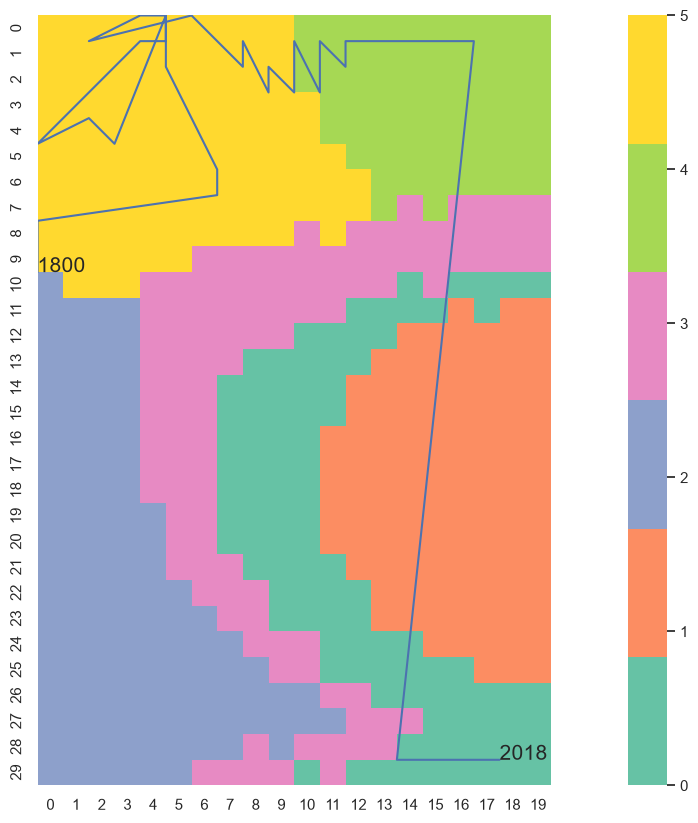

In [42]:
#crds_0 = som_win
fig = plt.figure(figsize=(20,10))
ax = fig.add_subplot(111, aspect='equal')
sns.heatmap(som_clust.reshape(30,20), cmap=clus_cmap)
plt.plot(country_crds[:,1], country_crds[:,0])
ax.text(country_crds[0,1], 
        country_crds[0,0], 
        r'1800', fontsize=15)
ax.text(country_crds[-1,1], 
        country_crds[-1,0], 
        r'2018', fontsize=15)

Next, we obtain aggregate values of the features for each cluster. This is a little involved. First we use the same function we created earlier to extract the SOM node for each observation in the full dataset. 

In [43]:
all_crds = np.apply_along_axis(get_node_crds, axis=1, arr=X)
all_crds

array([[10,  0],
       [ 9,  0],
       [ 9,  0],
       ...,
       [29,  6],
       [29,  6],
       [28, 13]], shape=(17676, 2))

Next we need an array of the cluster assignments for each node that corresponds to these node coordinates. TO do this, we reshape the 1D array `som_clust` to match the SOM grid:

In [44]:
som_clust_array = som_clust.reshape(30,20)

We now use the grid coordinates for each observation to extract the cluster number for the node to which that observation was assigned:

In [45]:
tmp_clust = som_clust_array[all_crds[:,0], all_crds[:,1]]

tmp_clust.shape

(17676,)

And finally, we merge this back into the original dataset, and use Panda's `mean()` function to calculate the mean by cluster:

In [46]:
gap_df_scale = gap_df_scale.assign(som_clust = tmp_clust)

gap_df_scale.groupby('som_clust').mean(numeric_only=True)

,year,child_mortality,fertility,per_cap_co2,income,life_expectancy,population
som_clust,,,,,,,
0,1985.584577,-0.970558,-0.962158,0.775400,0.844740,0.863692,0.254025
1,1995.725242,-1.498333,-1.489430,1.006324,1.327272,1.011262,-0.944628
2,1961.128510,0.637187,0.820424,-1.250846,-1.070113,-0.392587,0.068466
3,1963.382687,0.193556,0.415886,0.073463,-0.071325,0.224161,-0.605974
4,1968.201320,0.400824,0.613161,0.369468,0.257559,0.210486,1.182468
5,1904.695939,1.026033,0.637944,-0.437959,-0.648141,-1.372593,0.265674


This shows the approximate characteristics for the clusters (remember that the data are scaled so > 0 is above average and < 0 is below):

0. Low life expectancy and GDP, high mortality and fertility rates, small population
1. High life expectancy and GDP, lower mortality and fertility rates, medium population
2. Low life expectancy and GDP, very high mortality and fertility rates, medium population
3. High life expectancy and medium GDP, medium mortality and fertility rates, small population
4. High life expectancy and GDP, low mortality and fertility rates, medium population
5. Medium life expectancy, low GDP, medium mortality and fertility rates, large population

Note that there is also a progression in time, with clusters that tend to occur later having lower child mortality but higher CO2 emissions

And finally, we can plot out the spatial distribution of these clusters for any given year in the dataset. First we extract the year we want to visualize:

In [47]:
gap_df_2000 = gap_df_scale[gap_df_scale.year == 2000]
gap_df_2000

,country,year,child_mortality,fertility,per_cap_co2,income,life_expectancy,population,som_clust
200,Afghanistan,2000,0.304060,1.240771,-1.478372,-1.651689,0.038199,0.752357,2
501,Albania,2000,-0.951595,-1.232799,0.084916,0.171608,1.053372,-0.304686,0
802,Algeria,2000,-0.617570,-0.934063,0.598304,0.734110,1.014551,0.975067,0
1404,Angola,2000,0.670115,1.001150,-0.158718,-0.123907,-0.137064,0.619706,4
1705,Antigua and Barbuda,2000,-1.338116,-1.090649,0.826497,1.353397,1.044786,-2.379823,1
...,...,...,...,...,...,...,...,...,...
57390,Venezuela,2000,-1.093578,-0.702405,0.981972,1.041527,1.014551,0.836856,0
57691,Vietnam,2000,-0.839279,-1.375974,-0.101269,-0.489151,0.904184,1.503493,0
57992,Yemen,2000,0.063976,0.899745,0.013356,-0.099335,0.513002,0.652741,3
58293,Zambia,2000,0.482201,0.812751,-0.742035,-0.654618,-0.512203,0.365494,2


Again, we need to add the ISO3 country code to allow this to be merged with the country outlines:

In [48]:
gap_iso3 = coco.convert(names=gap_df_2000.country, to='ISO3', not_found=None)
gap_df_2000 = gap_df_2000.assign(ISO_A3 = gap_iso3)

In [49]:
borders2 = borders.merge(gap_df_2000, on='ISO_A3')
borders2.columns

Index(['featurecla', 'scalerank', 'LABELRANK', 'SOVEREIGNT', 'SOV_A3',
       'ADM0_DIF', 'LEVEL', 'TYPE', 'ADMIN', 'ADM0_A3',
       ...
       'geometry', 'country', 'year', 'child_mortality', 'fertility',
       'per_cap_co2', 'income', 'life_expectancy', 'population', 'som_clust'],
      dtype='str', length=104)

And finally, plot it:

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

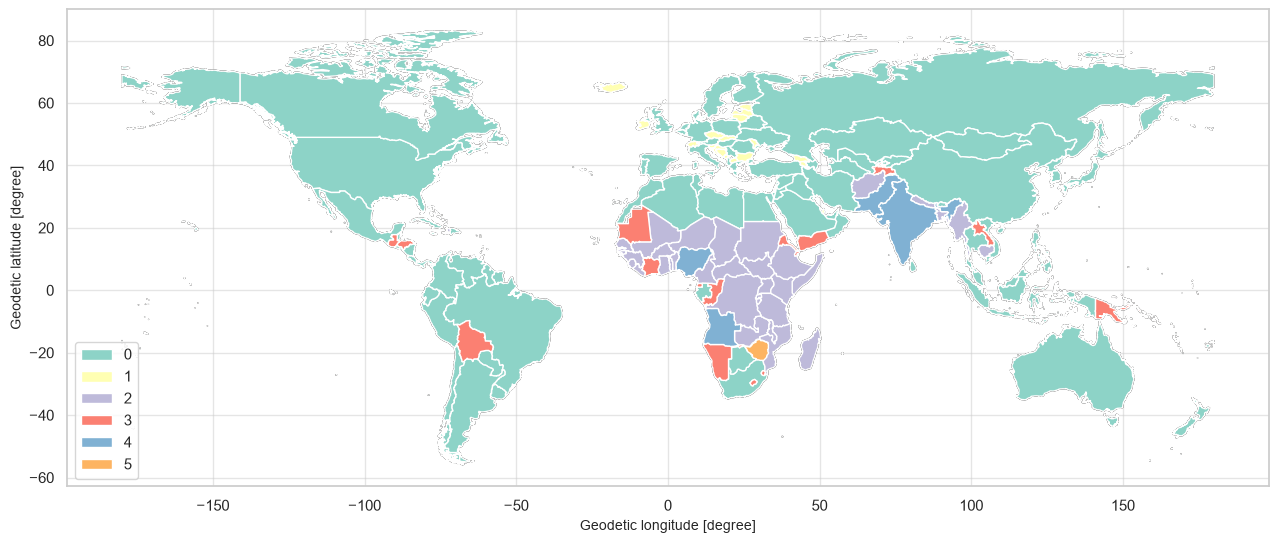

In [50]:
base = borders2.plot(figsize = (15.5, 9.5), edgecolor="black", facecolor="None")
borders2.plot(ax = base, column = 'som_clust', categorical=True, 
             cmap = 'Set3', legend = True, legend_kwds={'loc': 'lower left'})

# Exercise

For the exercise, you will need to build use an unsupervised classification method with the Atlantic Cancer dataset <a href="https://github.com/alexandster/geog3155/blob/main/datafiles/data_atlantic_1998_2012.csv" target="_blank">data_atlantic_1998_2012.csv</a>. This file contains information on cancer rates from around 660 counties in the eastern part of the US. There is also a shapefile with the polygons for each county <a href="https://github.com/alexandster/geog3155/tree/main/datafiles/COUNTY_ATLANTIC" target="_blank">COUNTY_ATLANTIC.shp</a>.

For the exercise, you will need to cluster these data and map out the resulting clusters. You will need to carry out the following steps:

- Read in the data and select the columns: `Cancer`, `Smoking`, `Poverty`, `PM25`, `SO2` and `NO2`
- Scale the data using a $z$-score transform
- Cluster the data using *either* $k$-means *or* a self-organizing map
- Extract the cluster number for each county and add it to the shapefile
- Make a map of the clusters
- [GEOG6155 students only]: Make a table showing the average values of each variable in each cluster

Use a new notebook to record your answers and output. These should be submitted to Canvas. Please use the following naming convention: `Lab06_lastname.ipynb`.


# Appendix 1

## Gap Minder Dataset

GapMinder dataset on global inequality (1800 to 2018): *gapminder_1800_2018.csv*

| Column header   | Variable                           |
|-----------------|------------------------------------|
| `country`         | Country name                       |
| `year`            | Year                               |
| `pop`             | Population                         |
| `child_mortality` | Child mortality rate (1000 births) |
| `fertility`       | Birth rate                         |
| `per_cap_co2`     | Per capita CO2 emissions           |
| `income`          | Mean income (\$)                   |
| `life_expectancy` | Mean life expectancy               |
| `population`      | Population size                    |

## Atlantic county cancer rates

*data_atlantic_1998_2012.csv*

| Column header   | Variable                          |
|-----------------|-----------------------------------|
| `FIPS`         | Country name                       |
| `x`            | Year                               |
| `y`             | Population                        |
| `Cancer` | Cancer mortality rate / 100,000          |
| `Poverty`       | Poverty rate (% below poverty level) |
| `Smoking`     | Smoking rate (%)                    |
| `PM25`          | Annual mean PM2.5 concentration   |
| `NO2` | Annual mean NO2 concentration               |
| `SO2`      | Annual mean SO2 concentration          |



## Appendix 2

Code to run and show the training values for the self-organized maps (will take a while to run)